# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [3]:
# Your data checks here
df.shape
df.dtypes
df.isna().sum()
df.duplicated().sum()
df.describe()





,user_id,movie_id,rating,age,year,decade,rating_year
count,100000.00000,100000.000000,100000.000000,100000.000000,99970.000000,99970.000000,100000.000000
mean,462.48475,425.530130,3.529860,32.969850,1987.748224,1982.780134,1997.471010
std,266.61442,330.798356,1.125674,11.562623,14.140014,13.820687,0.499161
min,1.00000,1.000000,1.000000,7.000000,1922.000000,1920.000000,1997.000000
25%,254.00000,175.000000,3.000000,24.000000,1986.000000,1980.000000,1997.000000
50%,447.00000,322.000000,4.000000,30.000000,1994.000000,1990.000000,1997.000000
75%,682.00000,631.000000,4.000000,40.000000,1996.000000,1990.000000,1998.000000
max,943.00000,1682.000000,5.000000,73.000000,1998.000000,1990.000000,1998.000000


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

When I used `df.shape`, I found 100,000 rows and 13 columns. When I checked `df.isna().sum()`, I found 30 missing values in both the `year` and `decade` columns. I also confirmed the nonmissing counts using `df.describe()`.

I decided to keep the dataset because the missing years don't affect every analysis. For example, I can still analyze movie ratings and genres. However, when analyzing movies by release year, I would exclude rows with missing years.

I also checked for duplicate rows and found 0 duplicates. The movie ratings range from 1 to 5, with an average rating of 3.53.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Count unique rated movies in each genre, allowing movies to belong to multiple genres.
- Why: One genre could misrepresent the genre distribution.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: I chose to calculate the average using individual movie ratings for each genre. I would also use confidence intervals to check how reliable the averages are.
- Why: I chose confidence intervals because some genres have fewer ratings than others. A genre with a high average rating doesn't necessarily mean better. Confidence intervals help me understand uncertainity around average rating.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: Use confidence intervals for yearly averages.
- Why: Some release years have more ratings than others. Confidence intervals help show uncertainty in yearly averages. Movies with missing release years should be excluded from this specific analysis.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: Calculate each movie's average using its individual ratings. Include movies with at least 50 ratings, then repeat with at least 150 ratings. If two movies have the same average, rank the movie with more ratings higher.
- Why: A movie with only a few ratings could have a misleadingly high average. Requiring at least 50 ratings provides a larger sample. Raising the minimum to 150 helps you see whether the top-five rankings change.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

Count unique rated movies in each genre, allowing movies to belong to multiple genres.


Fewest ratings by one user: 20
Most ratings by one user: 737
Number of rating years: 2
Rating years: [np.int64(1997), np.int64(1998)]


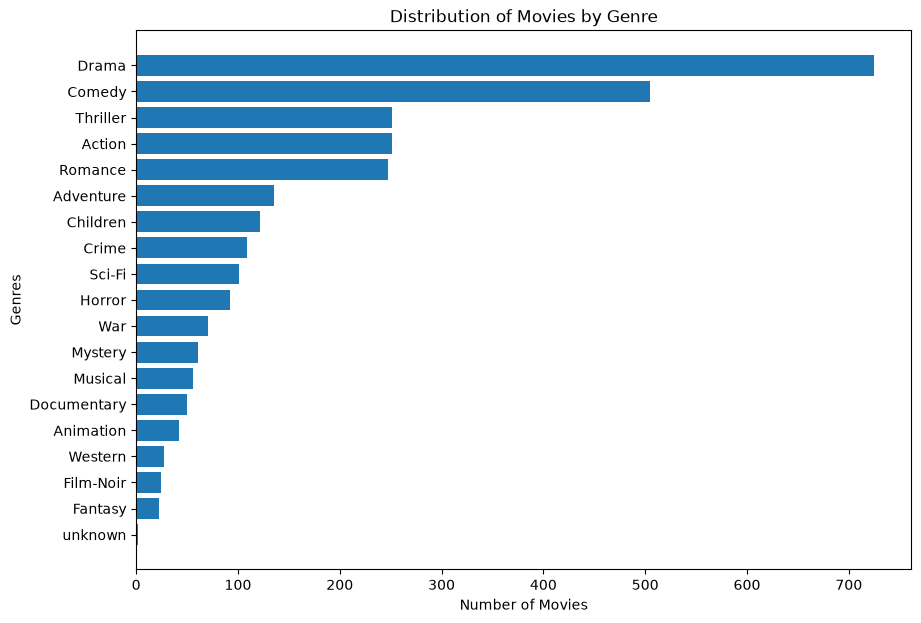

In [8]:
# Q1: your code here
unique_movies = df.drop_duplicates(subset="movie_id").copy()
unique_movies["genres"] = unique_movies["genres"].str.split("|")
exploded_movies = unique_movies.explode("genres")
exploded_movies["genres"].value_counts()

user_counts = df.groupby("user_id").size()

print("Fewest ratings by one user:", user_counts.min())
print("Most ratings by one user:", user_counts.max())
print("Number of rating years:", df["rating_year"].nunique())
print("Rating years:", sorted(df["rating_year"].dropna().unique()))

import matplotlib.pyplot as plt

# Count unique movies by genre
genre_counts = exploded_movies["genres"].value_counts()

# Create horizontal bar chart
plt.figure(figsize=(10, 7))
plt.barh(genre_counts.index, genre_counts.values)

# Add labels and title
plt.xlabel("Number of Movies")
plt.ylabel("Genres")
plt.title("Distribution of Movies by Genre")
plt.gca().invert_yaxis()

plt.show()


**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_
Drama and Comedy. Drama has 725 movies, compared with Comedy's 505. Unique rated movies belonging to each genre, including movies with multiple genres.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

Film-Noir has the highest average rating at 3.92, based on 1,733 ratings, followed by War at 3.82, based on 9,398 ratings. Fantasy has the lowest average among named genres at 3.22, based on 1,352 ratings. The unknown category is slightly lower at 3.20, but it only has 10 ratings.

,mean,count
genres,,
Film-Noir,3.921523,1733
War,3.815812,9398
Drama,3.687379,39895
Documentary,3.672823,758
Mystery,3.638132,5245
Crime,3.632278,8055
Romance,3.621705,19461
Western,3.613269,1854
Animation,3.576699,3605


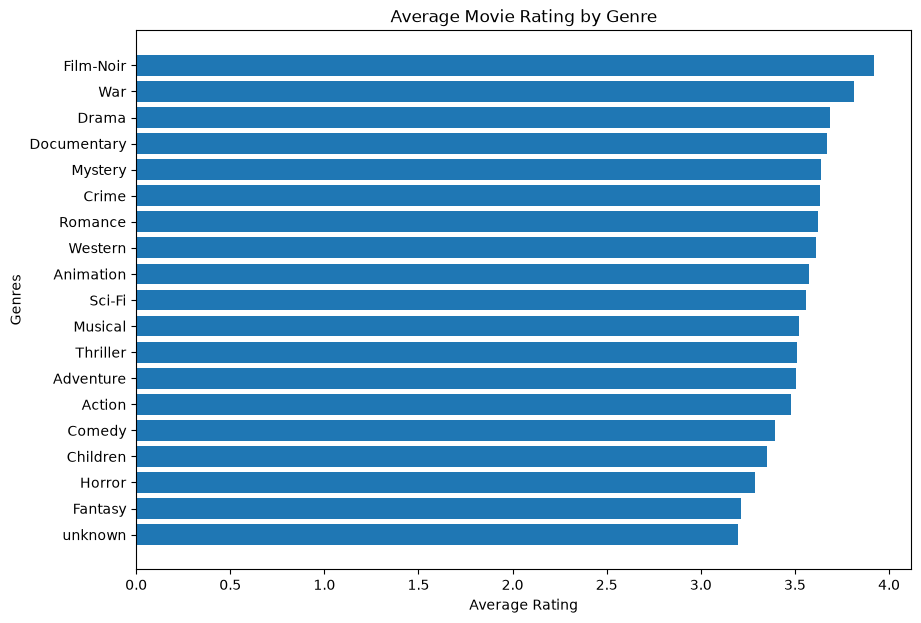

In [5]:
# Q2: your code here
ratings_by_genre = df.copy()
ratings_by_genre["genres"] = ratings_by_genre["genres"].str.split("|")
ratings_by_genre = ratings_by_genre.explode("genres")

genre_stats = ratings_by_genre.groupby("genres")["rating"].agg(["mean", "count"])
genre_stats = genre_stats.sort_values("mean", ascending=False)

display(genre_stats)

plt.figure(figsize=(10, 7))

plt.barh(genre_stats.index, genre_stats["mean"])

plt.xlabel("Average Rating")
plt.ylabel("Genres")
plt.title("Average Movie Rating by Genre")
plt.gca().invert_yaxis()

plt.show()

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

,mean,count,std
year,,,
1922.0,3.555556,54,1.075748
1926.0,3.000000,2,1.414214
1930.0,3.777778,18,0.646762
1931.0,4.000000,44,0.964486
1932.0,3.833333,12,0.389249
...,...,...,...
1994.0,3.420080,9034,1.129145
1995.0,3.414642,12389,1.141823
1996.0,3.311086,18744,1.142540


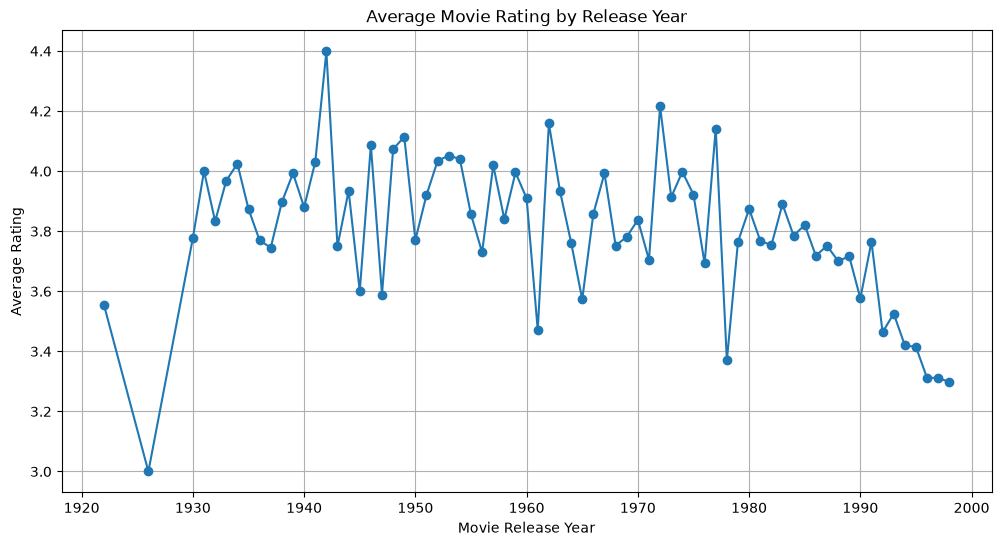

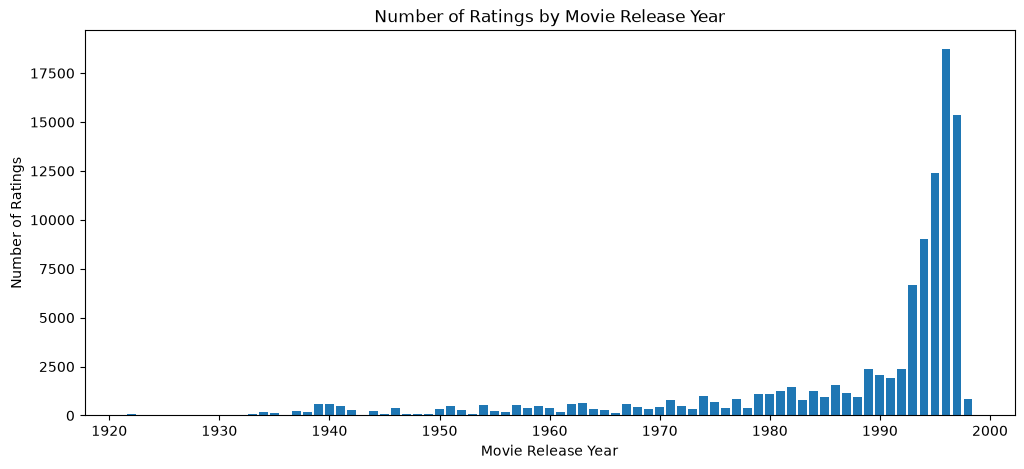

In [6]:
# Q3: your code here
year_data = df.dropna(subset=["year"]).copy()
year_data = df.dropna(subset=["year"]).copy()

year_stats = year_data.groupby("year")["rating"].agg(
    ["mean", "count", "std"]
)

display(year_stats)

plt.figure(figsize=(12, 6))

plt.plot(year_stats.index, year_stats["mean"], marker="o")

plt.xlabel("Movie Release Year")
plt.ylabel("Average Rating")
plt.title("Average Movie Rating by Release Year")

plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))

plt.bar(year_stats.index, year_stats["count"])

plt.xlabel("Movie Release Year")
plt.ylabel("Number of Ratings")
plt.title("Number of Ratings by Movie Release Year")

plt.show()

**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

The average movie rating changes across release years, but there is an overall downward trend for more recent movies. Thwe older movies often have higher average ratings, although their averages fluctuate more because they generally have fewer ratings. For example, movies released in 1931 have an average rating of 4.00 based on only 44 ratings, while movies released in 1996 have an average of 3.31 based on 18,744 ratings. This means the results are not equally reliable across all years.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [7]:
# Q4: your code here
movie_stats = df.groupby(["movie_id", "title"])["rating"].agg(
    ["mean", "count"]
)
movies_50 = movie_stats[movie_stats["count"] >= 50].sort_values(["mean", "count"], ascending=[False, False])
movies_150 = movie_stats[movie_stats["count"] >= 150]

movies_150 = movies_150.sort_values(
    ["mean", "count"], ascending=[False, False]
)

print("Top 5 Movies with at least 50 ratings")
display(movies_50.head(5))

print("Top 5 Movies with at least 150 ratings")
display(movies_150.head(5))

Top 5 Movies with at least 50 ratings


,,mean,count
movie_id,title,,
408,"Close Shave, A (1995)",4.491071,112
318,Schindler's List (1993),4.466443,298
169,"Wrong Trousers, The (1993)",4.466102,118
483,Casablanca (1942),4.456790,243
114,Wallace & Gromit: The Best of Aardman Animation (1996),4.447761,67


Top 5 Movies with at least 150 ratings


,,mean,count
movie_id,title,,
318,Schindler's List (1993),4.466443,298
483,Casablanca (1942),4.456790,243
64,"Shawshank Redemption, The (1994)",4.445230,283
603,Rear Window (1954),4.387560,209
12,"Usual Suspects, The (1995)",4.385768,267


**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_
When the minimum is 50 ratings, the top five movies are A Close Shave (4.49), Schindler's List (4.47), The Wrong Trousers (4.47), Casablanca (4.46), and Wallace & Gromit (4.45).

When I increase the minimum to 150 ratings, Schindler's List and Casablanca remain in the top five. A Close Shave, The Wrong Trousers, and Wallace & Gromit drop out because they have fewer than 150 ratings. They are replaced by The Shawshank Redemption (4.45), Rear Window (4.39), and The Usual Suspects (4.39).

This shows that increasing the minimum number of ratings changes the rankings. Movies with fewer ratings can have high averages, but requiring more ratings helps avoid relying on smaller samples.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

**Prompt 2**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q2**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q3**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q4**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

Q1: My Week 4 dashboard and Week 6 notebook gave me the same results. Drama had 725 movies, and Comedy had 505. Both methods counted unique movies using the movie ID and separated movies with multiple genres, 
which explains why the results matched. I trust the results more because I checked the counting method myself.

Q4: My dashboard and notebook also gave me the same top five movies for both minimum rating requirements. Both calculated the average rating for each movie, filtered movies with fewer than 50 or 150 ratings, and 
ranked them from highest to lowest. I trust the results more now because I checked the filtering and sorting steps myself instead of relying only on the AI-generated dashboard.


## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Horizontal bar chart
- Chart I used:  Horizontal bar chart
- Which communicates the answer better, and why? Both charts work well because they show the genres from highest to lowest and make it easy to compare the number of movies.
 I think the dashboard chart is slightly better because it is sorted and easier to read.

**Q2**
- Chart the dashboard used: Vertical bar chart
- Chart I used: Horizontal bar chart
- Which communicates the answer better, and why? I prefer my horizontal bar chart because the genre names are easier to read. The dashboard's vertical chart has labels at an angle, making comparisons a little harder. 
My notebook also shows the number of ratings in a separate table.

**Q3**
- Chart the dashboard used:  Line chart
- Chart I used:  Line chart and a separate bar chart showing rating counts.
- Which communicates the answer better, and why? I prefer my notebook because it shows both the average rating and the number of ratings for each release year. 
The dashboard only shows the average rating trend, so it is harder to tell which years have enough ratings to support their averages.

**Q4**
- Chart the dashboard used: Two horizontal bar charts and tables
- Chart I used: Two tables showing the top five movies.
- Which communicates the answer better, and why? I prefer my tables because I can see the movie titles, average ratings, and number of ratings clearly. The dashboard charts are harder to read because some movie titles are long and the charts are small.


Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*


**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

1. The fewest ratings given by one user was 20, while the most was 737. This shows that some users contributed a lot more ratings than others. The dataset only includes people who rated movies on the platform, so it doesn't represent everyone. This could affect my Q2 results because people who rate more movies have a bigger influence on the genre averages.

3. The dataset only has two rating years, 1997 and 1998. My chart shows that older movies generally have higher average ratings than newer movies, but this doesn't mean people's tastes changed over time. The chart compares movie release years, not when people rated them. Older movies might have higher ratings because people are more likely to watch and rate well-known classics.

5. A studio executive might think Film-Noir is the best genre to invest in because it has the highest average rating of 3.92. However, Film-Noir only has 1,733 ratings compared with Drama's 39,895 ratings. A higher average doesn't necessarily mean a genre is more popular or will make more money.

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

I would change how the AI displayed some of the charts. For example, the Q4 movie titles were difficult to read in the dashboard because the charts were too small. My tables made it easier to compare the movie titles, average ratings, and number of ratings.

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

The AI did a good job calculating the results. When I compared my Week 4 dashboard with my Week 6 notebook, all four questions gave me the same main results. I was surprised that the calculations matched even though I worked through them myself.

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?
In Week 4, I relied more on AI to build my dashboard, but in Week 6, I took more control by writing the code myself, checking the results, and deciding which charts worked better.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week